In [2]:
import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Basic libraries imported successfully!")

Pandas version: 3.0.6
NumPy version: 2.5.3
Basic libraries imported successfully!


In [3]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)
print("Scikit-learn imported successfully!")

Scikit-learn version: 1.9.1
Scikit-learn imported successfully!


In [4]:
import pandas as pd
from pathlib import Path

# Find CSV files in the project folders
project_path = Path.cwd()

csv_files = list(project_path.rglob("*.csv"))

print("CSV files found:")
for file in csv_files:
    print(file)

CSV files found:
c:\Internship_project\Data\day18_model_evaluation_report.csv
c:\Internship_project\Data\day19_model_comparison_report.csv
c:\Internship_project\Data\day20_student_performance_report.csv
c:\Internship_project\Data\student_performance_report.csv
c:\Internship_project\Data\Data\day15_student_risk_report.csv
c:\Internship_project\Data\Data\day16_ml_prediction_report.csv
c:\Internship_project\Data\Data\day21_student_performance_classification_report.csv


In [5]:
import pandas as pd

file_path = r"C:\Internship_project\Data\day20_student_performance_report.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (3, 3)

Column names:
['Actual_Marks', 'Predicted_Marks', 'Absolute_Error']

First 5 rows:


,Actual_Marks,Predicted_Marks,Absolute_Error
0,64,65.29,1.29
1,42,43.18,1.18
2,48,46.51,1.49


In [6]:
# Day 22: Dataset Inspection

print("Dataset Information:")
print("-" * 40)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

Dataset Information:
----------------------------------------
Number of rows: 3
Number of columns: 3

Column Names:
['Actual_Marks', 'Predicted_Marks', 'Absolute_Error']

Missing Values:
Actual_Marks       0
Predicted_Marks    0
Absolute_Error     0
dtype: int64

Data Types:
Actual_Marks         int64
Predicted_Marks    float64
Absolute_Error     float64
dtype: object

First 5 Rows:


,Actual_Marks,Predicted_Marks,Absolute_Error
0,64,65.29,1.29
1,42,43.18,1.18
2,48,46.51,1.49


In [7]:
# Day 22: Identify Target Column

print("Available columns:")
for column in df.columns:
    print("-", column)

print("\nDataset preview:")
display(df.head(10))

print("\nUnique values in each column:")
for column in df.columns:
    print(f"\n{column}:")
    print(df[column].unique()[:10])

Available columns:
- Actual_Marks
- Predicted_Marks
- Absolute_Error

Dataset preview:


,Actual_Marks,Predicted_Marks,Absolute_Error
0,64,65.29,1.29
1,42,43.18,1.18
2,48,46.51,1.49



Unique values in each column:

Actual_Marks:
[64 42 48]

Predicted_Marks:
[65.29 43.18 46.51]

Absolute_Error:
[1.29 1.18 1.49]


In [8]:
# Day 22: Check whether the dataset is suitable for training

print("Dataset columns:")
print(df.columns.tolist())

print("\nDataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

Dataset columns:
['Actual_Marks', 'Predicted_Marks', 'Absolute_Error']

Dataset shape: (3, 3)

First 5 rows:


,Actual_Marks,Predicted_Marks,Absolute_Error
0,64,65.29,1.29
1,42,43.18,1.18
2,48,46.51,1.49



Data types:
Actual_Marks         int64
Predicted_Marks    float64
Absolute_Error     float64
dtype: object


In [9]:
# Day 22: Data Cleaning

print("Rows before cleaning:", len(df))

# Count duplicate rows
duplicate_count = df.duplicated().sum()
print("Duplicate rows found:", duplicate_count)

# Remove duplicate rows
df = df.drop_duplicates().copy()

print("Rows after removing duplicates:", len(df))

# Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDataset after cleaning:")
display(df.head())

Rows before cleaning: 3
Duplicate rows found: 0
Rows after removing duplicates: 3

Missing values in each column:
Actual_Marks       0
Predicted_Marks    0
Absolute_Error     0
dtype: int64

Dataset after cleaning:


,Actual_Marks,Predicted_Marks,Absolute_Error
0,64,65.29,1.29
1,42,43.18,1.18
2,48,46.51,1.49


In [10]:
# Day 22: Handle Missing Values

print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing numeric values with the median
numeric_columns = df.select_dtypes(include="number").columns

for column in numeric_columns:
    if df[column].isnull().any():
        df[column] = df[column].fillna(df[column].median())

# Fill missing text values with the most frequent value
categorical_columns = df.select_dtypes(
    include=["object", "category", "string"]
).columns

for column in categorical_columns:
    if df[column].isnull().any():
        mode_values = df[column].mode(dropna=True)
        if not mode_values.empty:
            df[column] = df[column].fillna(mode_values.iloc[0])

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDataset shape:", df.shape)

Missing values before cleaning:
Actual_Marks       0
Predicted_Marks    0
Absolute_Error     0
dtype: int64

Missing values after cleaning:
Actual_Marks       0
Predicted_Marks    0
Absolute_Error     0
dtype: int64

Dataset shape: (3, 3)


In [11]:
# Day 22: Statistical Analysis

print("Statistical Summary of Student Performance Dataset")
print("=" * 55)

display(df.describe())

print("\nDataset Information:")
df.info()

print("\nNumber of Unique Values in Each Column:")
print(df.nunique())

Statistical Summary of Student Performance Dataset


,Actual_Marks,Predicted_Marks,Absolute_Error
count,3.000000,3.000000,3.000000
mean,51.333333,51.660000,1.320000
std,11.372481,11.920776,0.157162
min,42.000000,43.180000,1.180000
25%,45.000000,44.845000,1.235000
50%,48.000000,46.510000,1.290000
75%,56.000000,55.900000,1.390000
max,64.000000,65.290000,1.490000



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Actual_Marks     3 non-null      int64  
 1   Predicted_Marks  3 non-null      float64
 2   Absolute_Error   3 non-null      float64
dtypes: float64(2), int64(1)
memory usage: 204.0 bytes

Number of Unique Values in Each Column:
Actual_Marks       3
Predicted_Marks    3
Absolute_Error     3
dtype: int64


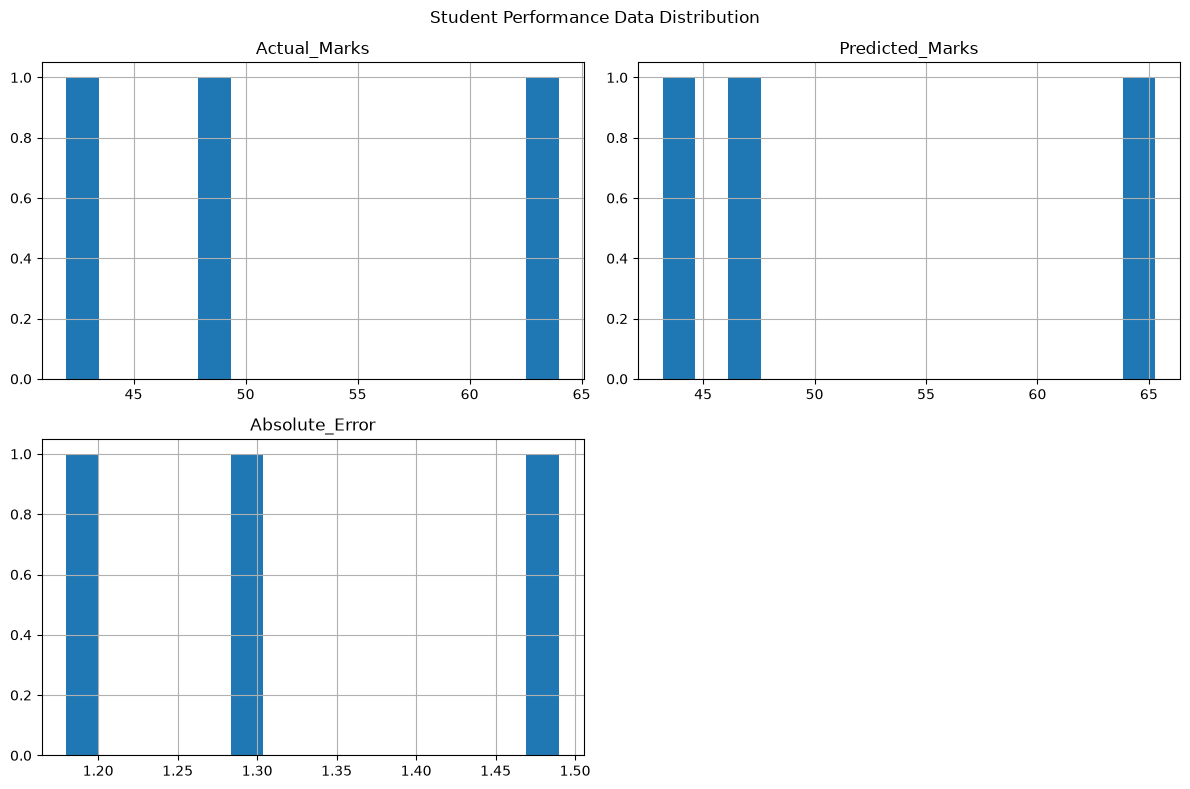

In [12]:
# Day 22: Data Visualization

import matplotlib.pyplot as plt

numeric_df = df.select_dtypes(include="number")

if numeric_df.empty:
    print("No numeric columns available for visualization.")
else:
    numeric_df.hist(figsize=(12, 8), bins=15)
    plt.suptitle("Student Performance Data Distribution")
    plt.tight_layout()
    plt.show()

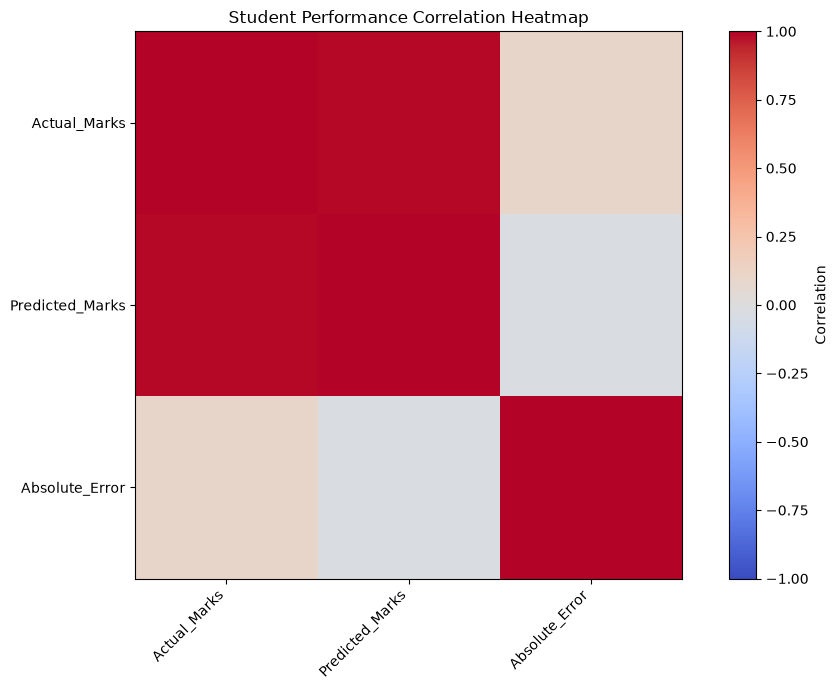

In [14]:
# Day 22: Correlation Heatmap without Seaborn

import matplotlib.pyplot as plt

numeric_df = df.select_dtypes(include="number")

if numeric_df.shape[1] < 2:
    print("At least two numeric columns are required.")
else:
    correlation_matrix = numeric_df.corr()

    plt.figure(figsize=(10, 7))
    plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

    plt.colorbar(label="Correlation")
    plt.xticks(
        range(len(correlation_matrix.columns)),
        correlation_matrix.columns,
        rotation=45,
        ha="right"
    )
    plt.yticks(
        range(len(correlation_matrix.columns)),
        correlation_matrix.columns
    )

    plt.title("Student Performance Correlation Heatmap")
    plt.tight_layout()
    plt.show()

In [15]:
# Day 22: Categorical Data Encoding

from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

categorical_columns = df_encoded.select_dtypes(
    include=["object", "category", "string"]
).columns

label_encoders = {}

for column in categorical_columns:
    encoder = LabelEncoder()
    df_encoded[column] = encoder.fit_transform(
        df_encoded[column].astype(str)
    )
    label_encoders[column] = encoder

print("Categorical columns encoded successfully!")

print("\nEncoded Dataset:")
display(df_encoded.head())

print("\nData Types After Encoding:")
print(df_encoded.dtypes)

Categorical columns encoded successfully!

Encoded Dataset:


,Actual_Marks,Predicted_Marks,Absolute_Error
0,64,65.29,1.29
1,42,43.18,1.18
2,48,46.51,1.49



Data Types After Encoding:
Actual_Marks         int64
Predicted_Marks    float64
Absolute_Error     float64
dtype: object


In [16]:
# Day 22: Check Target Column

print("Available columns:")
print(df_encoded.columns.tolist())

print("\nDataset preview:")
display(df_encoded.head(10))

print("\nUnique values in each column:")
for column in df_encoded.columns:
    print(f"\n{column}:")
    print(df_encoded[column].unique()[:10])

Available columns:
['Actual_Marks', 'Predicted_Marks', 'Absolute_Error']

Dataset preview:


,Actual_Marks,Predicted_Marks,Absolute_Error
0,64,65.29,1.29
1,42,43.18,1.18
2,48,46.51,1.49



Unique values in each column:

Actual_Marks:
[64 42 48]

Predicted_Marks:
[65.29 43.18 46.51]

Absolute_Error:
[1.29 1.18 1.49]


In [17]:
# Day 22: Create Sample Student Performance Dataset

import pandas as pd

data = {
    "study_hours": [2, 5, 1, 7, 4, 8, 3, 6, 2, 9,
                    5, 1, 7, 4, 8, 3, 6, 2, 9, 5],
    "attendance": [60, 85, 50, 95, 75, 98, 65, 90, 55, 99,
                   80, 45, 92, 70, 96, 62, 88, 58, 100, 82],
    "previous_score": [45, 75, 35, 90, 65, 95, 50, 85, 40, 98,
                       72, 30, 88, 60, 94, 48, 80, 42, 99, 76],
    "assignments_completed": [4, 9, 3, 10, 7, 10, 5, 9, 4, 10,
                              8, 2, 10, 6, 10, 4, 9, 3, 10, 8],
    "performance": [
        "Low", "High", "Low", "High", "Medium",
        "High", "Low", "High", "Low", "High",
        "High", "Low", "High", "Medium", "High",
        "Low", "High", "Low", "High", "High"
    ]
}

student_df = pd.DataFrame(data)

print("Sample dataset created successfully!")
print("Dataset shape:", student_df.shape)

display(student_df.head(10))

Sample dataset created successfully!
Dataset shape: (20, 5)


,study_hours,attendance,previous_score,assignments_completed,performance
0,2,60,45,4,Low
1,5,85,75,9,High
2,1,50,35,3,Low
3,7,95,90,10,High
4,4,75,65,7,Medium
5,8,98,95,10,High
6,3,65,50,5,Low
7,6,90,85,9,High
8,2,55,40,4,Low
9,9,99,98,10,High


In [18]:
# Day 22: Select Features and Target

# Input features
X = student_df[
    [
        "study_hours",
        "attendance",
        "previous_score",
        "assignments_completed"
    ]
]

# Target column
y = student_df["performance"]

print("Features (X):")
display(X.head())

print("\nTarget (y):")
display(y.head())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

print("\nPerformance categories:")
print(y.value_counts())

Features (X):


,study_hours,attendance,previous_score,assignments_completed
0,2,60,45,4
1,5,85,75,9
2,1,50,35,3
3,7,95,90,10
4,4,75,65,7



Target (y):


0       Low
1      High
2       Low
3      High
4    Medium
Name: performance, dtype: str


Feature shape: (20, 4)
Target shape: (20,)

Performance categories:
performance
High      11
Low        7
Medium     2
Name: count, dtype: int64


In [19]:
# Day 22: Split Dataset

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Dataset split completed successfully!")

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Dataset split completed successfully!
Training features: (15, 4)
Testing features: (5, 4)
Training target: (15,)
Testing target: (5,)


In [22]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest import successful!")

Random Forest import successful!


In [23]:
from sklearn.ensemble import RandomForestClassifier

# Create the model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [24]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Make predictions on the test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", round(accuracy, 3))

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=["Low", "Medium", "High"]))

Model Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00         3
         Low       1.00      1.00      1.00         2

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5


Confusion Matrix:
[[2 0 0]
 [0 0 0]
 [0 0 3]]


,Actual Performance,Predicted Performance
0,High,High
1,Low,Low
2,High,High
3,Low,Low
4,High,High


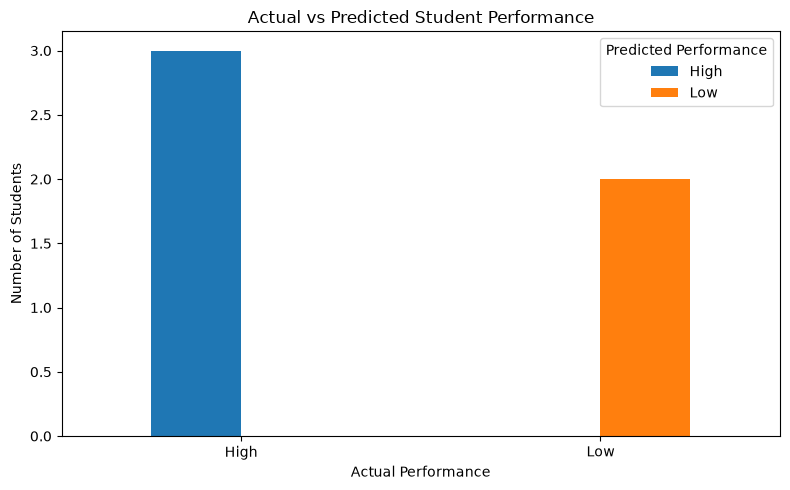

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

# Compare actual and predicted results
results_df = pd.DataFrame({
    "Actual Performance": y_test.values,
    "Predicted Performance": y_pred
})

display(results_df)

# Plot actual vs predicted performance
comparison = pd.crosstab(
    results_df["Actual Performance"],
    results_df["Predicted Performance"]
)

comparison.plot(kind="bar", figsize=(8, 5))

plt.title("Actual vs Predicted Student Performance")
plt.xlabel("Actual Performance")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [26]:
# Example data for a new student
new_student = pd.DataFrame({
    "study_hours": [6],
    "attendance": [90],
    "previous_score": [78],
    "assignments_completed": [9]
})

# Predict student performance
prediction = model.predict(new_student)

print("Predicted Student Performance:", prediction[0])

Predicted Student Performance: High


,Feature,Importance
1,attendance,0.284314
0,study_hours,0.247337
2,previous_score,0.241770
3,assignments_completed,0.226579


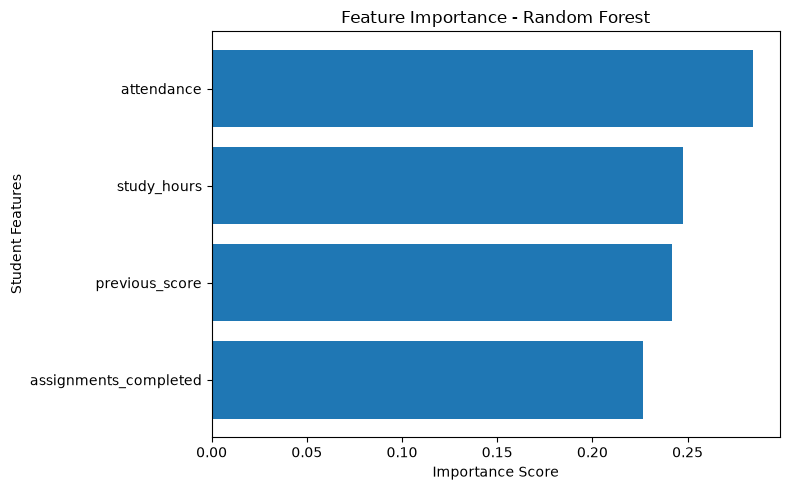

In [27]:
# Get feature importance scores
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

# Plot feature importance
plt.figure(figsize=(8, 5))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Student Features")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [28]:
# Create a results DataFrame
prediction_results = pd.DataFrame({
    "Actual_Performance": y_test.to_numpy(),
    "Predicted_Performance": y_pred
})

# Save results to CSV
output_path = r"C:\Internship_project\Data\day22_student_performance_predictions.csv"

prediction_results.to_csv(output_path, index=False)

print("Prediction results saved successfully!")
print("Saved at:", output_path)

display(prediction_results)

Prediction results saved successfully!
Saved at: C:\Internship_project\Data\day22_student_performance_predictions.csv


,Actual_Performance,Predicted_Performance
0,High,High
1,Low,Low
2,High,High
3,Low,Low
4,High,High


In [29]:
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

# Generate the classification report
report = classification_report(
    y_test,
    y_pred,
    output_dict=True,
    zero_division=0
)

# Convert report to a DataFrame
report_df = pd.DataFrame(report).transpose()

# Save evaluation report
report_path = r"C:\Internship_project\Data\day22_model_evaluation_report.csv"
report_df.to_csv(report_path, index=True)

print("Model evaluation report saved successfully!")
print("Accuracy:", round(accuracy, 3))
print("Report saved at:", report_path)

display(report_df)

Model evaluation report saved successfully!
Accuracy: 1.0
Report saved at: C:\Internship_project\Data\day22_model_evaluation_report.csv


,precision,recall,f1-score,support
High,1.0,1.0,1.0,3.0
Low,1.0,1.0,1.0,2.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,5.0
weighted avg,1.0,1.0,1.0,5.0


In [30]:
import joblib
import os

# Create the models folder if it doesn't exist
model_folder = r"C:\Internship_project\models"
os.makedirs(model_folder, exist_ok=True)

# Save the trained model
model_path = os.path.join(
    model_folder,
    "day22_student_performance_model.pkl"
)

joblib.dump(model, model_path)

print("Model saved successfully!")
print("Saved at:", model_path)

Model saved successfully!
Saved at: C:\Internship_project\models\day22_student_performance_model.pkl


In [31]:
import joblib

# Load the saved model
loaded_model = joblib.load(
    r"C:\Internship_project\models\day22_student_performance_model.pkl"
)

# Predict performance for the new student
loaded_prediction = loaded_model.predict(new_student)

print("Loaded model successfully!")
print("Predicted student performance:", loaded_prediction[0])

Loaded model successfully!
Predicted student performance: High


In [32]:
summary = {
    "Project": "Student Performance Prediction System",
    "Day": 22,
    "Algorithm": "Random Forest Classifier",
    "Input Features": [
        "Study Hours",
        "Attendance",
        "Previous Score",
        "Assignments Completed"
    ],
    "Target": "Student Performance",
    "Classes": ["Low", "Medium", "High"],
    "Evaluation Metric": "Accuracy, Precision, Recall, F1-score",
    "Model File": "day22_student_performance_model.pkl",
    "Dataset": "Synthetic sample data for demonstration"
}

for key, value in summary.items():
    print(f"{key}: {value}")

Project: Student Performance Prediction System
Day: 22
Algorithm: Random Forest Classifier
Input Features: ['Study Hours', 'Attendance', 'Previous Score', 'Assignments Completed']
Target: Student Performance
Classes: ['Low', 'Medium', 'High']
Evaluation Metric: Accuracy, Precision, Recall, F1-score
Model File: day22_student_performance_model.pkl
Dataset: Synthetic sample data for demonstration


In [33]:
import pandas as pd

# Convert the summary into a DataFrame
summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["項目", "Details"]
)

# Save the summary
summary_path = r"C:\Internship_project\Data\day22_project_summary.csv"
summary_df.to_csv(summary_path, index=False)

print("Project summary saved successfully!")
print("Saved at:", summary_path)

display(summary_df)

Project summary saved successfully!
Saved at: C:\Internship_project\Data\day22_project_summary.csv


,項目,Details
0,Project,Student Performance Prediction System
1,Day,22
2,Algorithm,Random Forest Classifier
3,Input Features,"[Study Hours, Attendance, Previous Score, Assi..."
4,Target,Student Performance
5,Classes,"[Low, Medium, High]"
6,Evaluation Metric,"Accuracy, Precision, Recall, F1-score"
7,Model File,day22_student_performance_model.pkl
8,Dataset,Synthetic sample data for demonstration


In [34]:
report_text = """
DAY 22: STUDENT PERFORMANCE PREDICTION SYSTEM

1. Objective
Build a machine learning model to classify student performance.

2. Algorithm
Random Forest Classifier.

3. Input Features
- Study Hours
- Attendance
- Previous Score
- Assignments Completed

4. Target Classes
- Low
- Medium
- High

5. Model Evaluation
The model was evaluated using accuracy, precision, recall,
F1-score, and a confusion matrix.

6. Model Saving
The trained model was saved as:
day22_student_performance_model.pkl

7. Conclusion
This project demonstrates how a Random Forest classifier
can predict performance categories from input features.

Note: The project uses a small synthetic dataset for
demonstration. Results are not validated for real-world use.
"""

report_path = r"C:\Internship_project\Data\day22_student_performance_report.txt"

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report_text)

print("Project report saved successfully!")
print("Saved at:", report_path)

Project report saved successfully!
Saved at: C:\Internship_project\Data\day22_student_performance_report.txt


In [35]:
import os

files_to_check = [
    r"C:\Internship_project\Data\day22_student_performance_predictions.csv",
    r"C:\Internship_project\Data\day22_model_evaluation_report.csv",
    r"C:\Internship_project\Data\day22_project_summary.csv",
    r"C:\Internship_project\Data\day22_student_performance_report.txt",
    r"C:\Internship_project\models\day22_student_performance_model.pkl"
]

print("DAY 22 PROJECT FILE CHECK\n")

for file_path in files_to_check:
    status = "FOUND" if os.path.exists(file_path) else "NOT FOUND"
    print(f"{status}: {os.path.basename(file_path)}")

DAY 22 PROJECT FILE CHECK

FOUND: day22_student_performance_predictions.csv
FOUND: day22_model_evaluation_report.csv
FOUND: day22_project_summary.csv
FOUND: day22_student_performance_report.txt
FOUND: day22_student_performance_model.pkl
